In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import data that describe countries in one point

In [2]:
countries_win = pd.read_parquet('../data/one_point_win_no_multicollinearity.parquet')

In [3]:
countries_win.head()

,labor_force_mean,livestock_prod_mean,livestock_prod_std,livestock_prod_min,urban_pop_mean,gov_exp_mean,gov_exp_cv,reserves_mean,reserves_cv,investment_cv,...,inflation__skew,edu_spending__growth,edu_spending__skew,edu_spending__kurtosis,govermment_effective__cv,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,Country
0,2.679788,4.582413,1.820075,4.541165,4.456624,4.727279,0.195843,4.319984,0.133817,0.156194,...,-0.292617,-0.027544,-0.495494,-0.667223,0.138675,-0.183282,-0.557676,0.418830,0.517477,Australia
1,1.736775,4.614130,1.027869,4.606170,4.128134,3.082838,0.135154,3.253361,0.161904,0.129163,...,0.208691,-0.608596,-0.898845,-0.712542,0.138675,-0.219351,-0.255483,0.418830,-0.060887,Austria
2,1.825355,4.636378,1.027869,4.606170,4.473933,3.409761,0.133181,3.394961,0.213816,0.138859,...,0.842201,0.201990,0.929855,0.516924,0.138675,-0.262785,0.825197,-0.006636,-0.915149,Belgium
3,3.719821,4.672829,1.646041,4.603168,4.465115,5.994841,0.187350,5.892785,0.110773,0.241721,...,0.211311,-0.552472,-0.241833,-0.753368,0.138675,-0.126735,0.825197,-0.714821,-0.915149,Brazil
4,1.448095,4.582413,1.688591,4.541165,4.324358,2.358375,0.229568,4.022525,0.200555,0.230937,...,0.842201,0.790948,-0.898845,-0.085581,0.138675,-0.268474,-0.822060,0.057350,-0.412401,Bulgaria


### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [4]:
from sklearn.cluster import KMeans

In [5]:
from sklearn.metrics import silhouette_samples

In [6]:
from matplotlib import cm

In [7]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

In [8]:
import country_converter as coco

In [9]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

In [10]:
cluster_input = countries_win.select_dtypes(include='number')
cluster_input.head()

,labor_force_mean,livestock_prod_mean,livestock_prod_std,livestock_prod_min,urban_pop_mean,gov_exp_mean,gov_exp_cv,reserves_mean,reserves_cv,investment_cv,...,inflation__growth,inflation__skew,edu_spending__growth,edu_spending__skew,edu_spending__kurtosis,govermment_effective__cv,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,2.679788,4.582413,1.820075,4.541165,4.456624,4.727279,0.195843,4.319984,0.133817,0.156194,...,-0.180908,-0.292617,-0.027544,-0.495494,-0.667223,0.138675,-0.183282,-0.557676,0.418830,0.517477
1,1.736775,4.614130,1.027869,4.606170,4.128134,3.082838,0.135154,3.253361,0.161904,0.129163,...,-0.365941,0.208691,-0.608596,-0.898845,-0.712542,0.138675,-0.219351,-0.255483,0.418830,-0.060887
2,1.825355,4.636378,1.027869,4.606170,4.473933,3.409761,0.133181,3.394961,0.213816,0.138859,...,-0.307831,0.842201,0.201990,0.929855,0.516924,0.138675,-0.262785,0.825197,-0.006636,-0.915149
3,3.719821,4.672829,1.646041,4.603168,4.465115,5.994841,0.187350,5.892785,0.110773,0.241721,...,-0.418923,0.211311,-0.552472,-0.241833,-0.753368,0.138675,-0.126735,0.825197,-0.714821,-0.915149
4,1.448095,4.582413,1.688591,4.541165,4.324358,2.358375,0.229568,4.022525,0.200555,0.230937,...,-0.564481,0.842201,0.790948,-0.898845,-0.085581,0.138675,-0.268474,-0.822060,0.057350,-0.412401


#### Using the elbow method to find the optimal number of clusters

In [11]:
distortions = []

In [12]:
import time

In [13]:
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


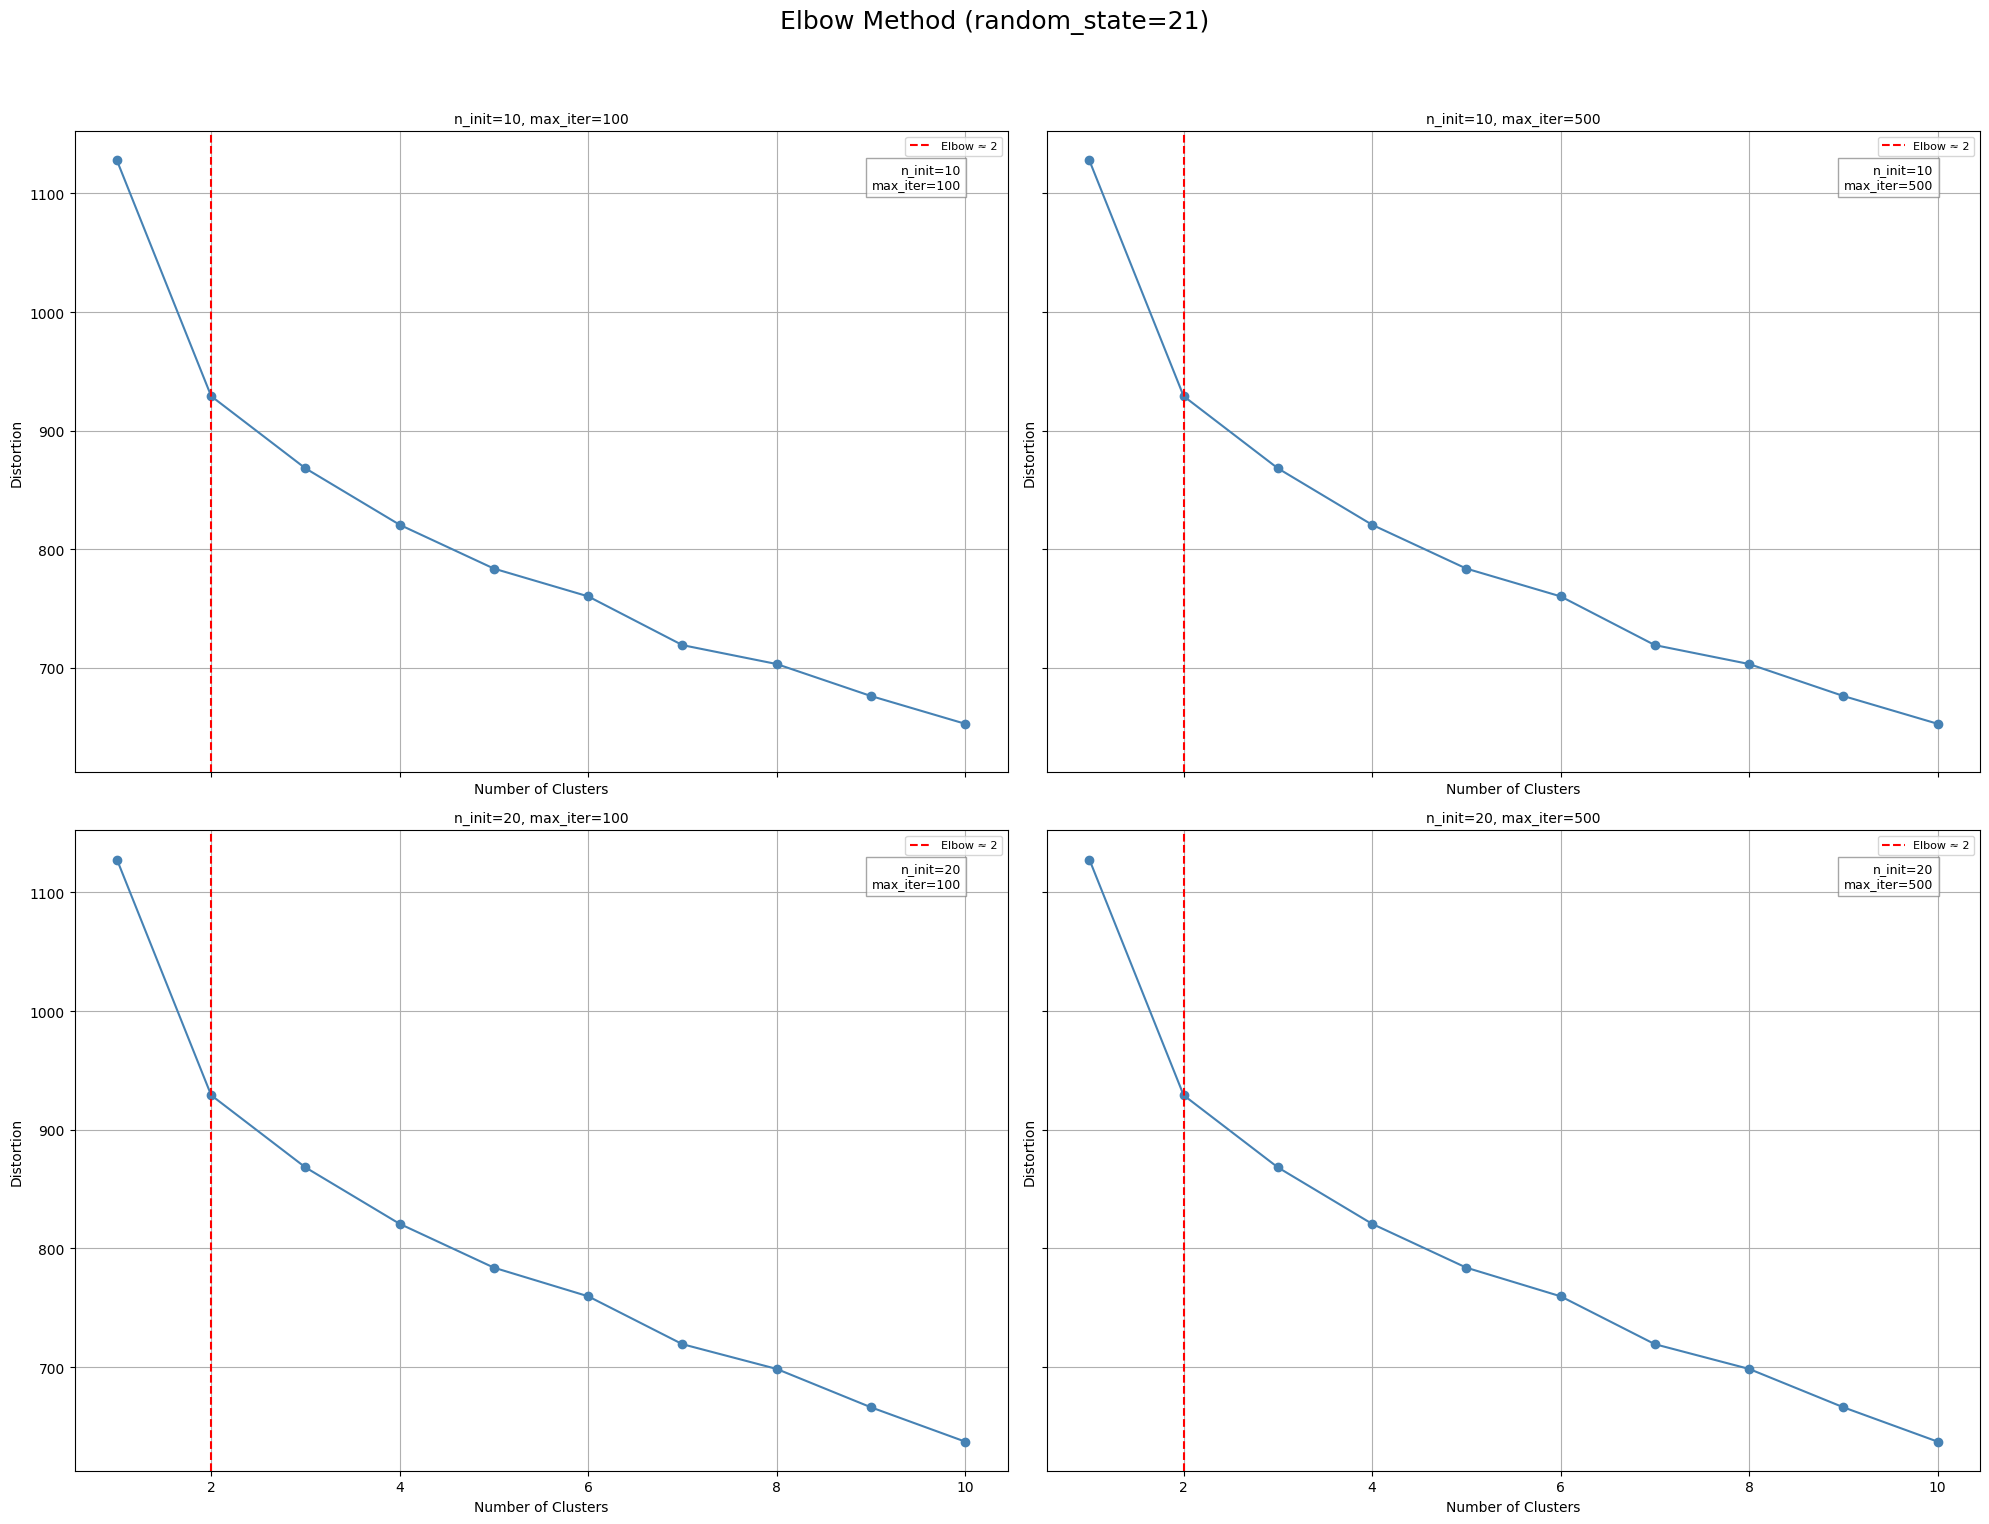


Running elbow plots for random_state=42


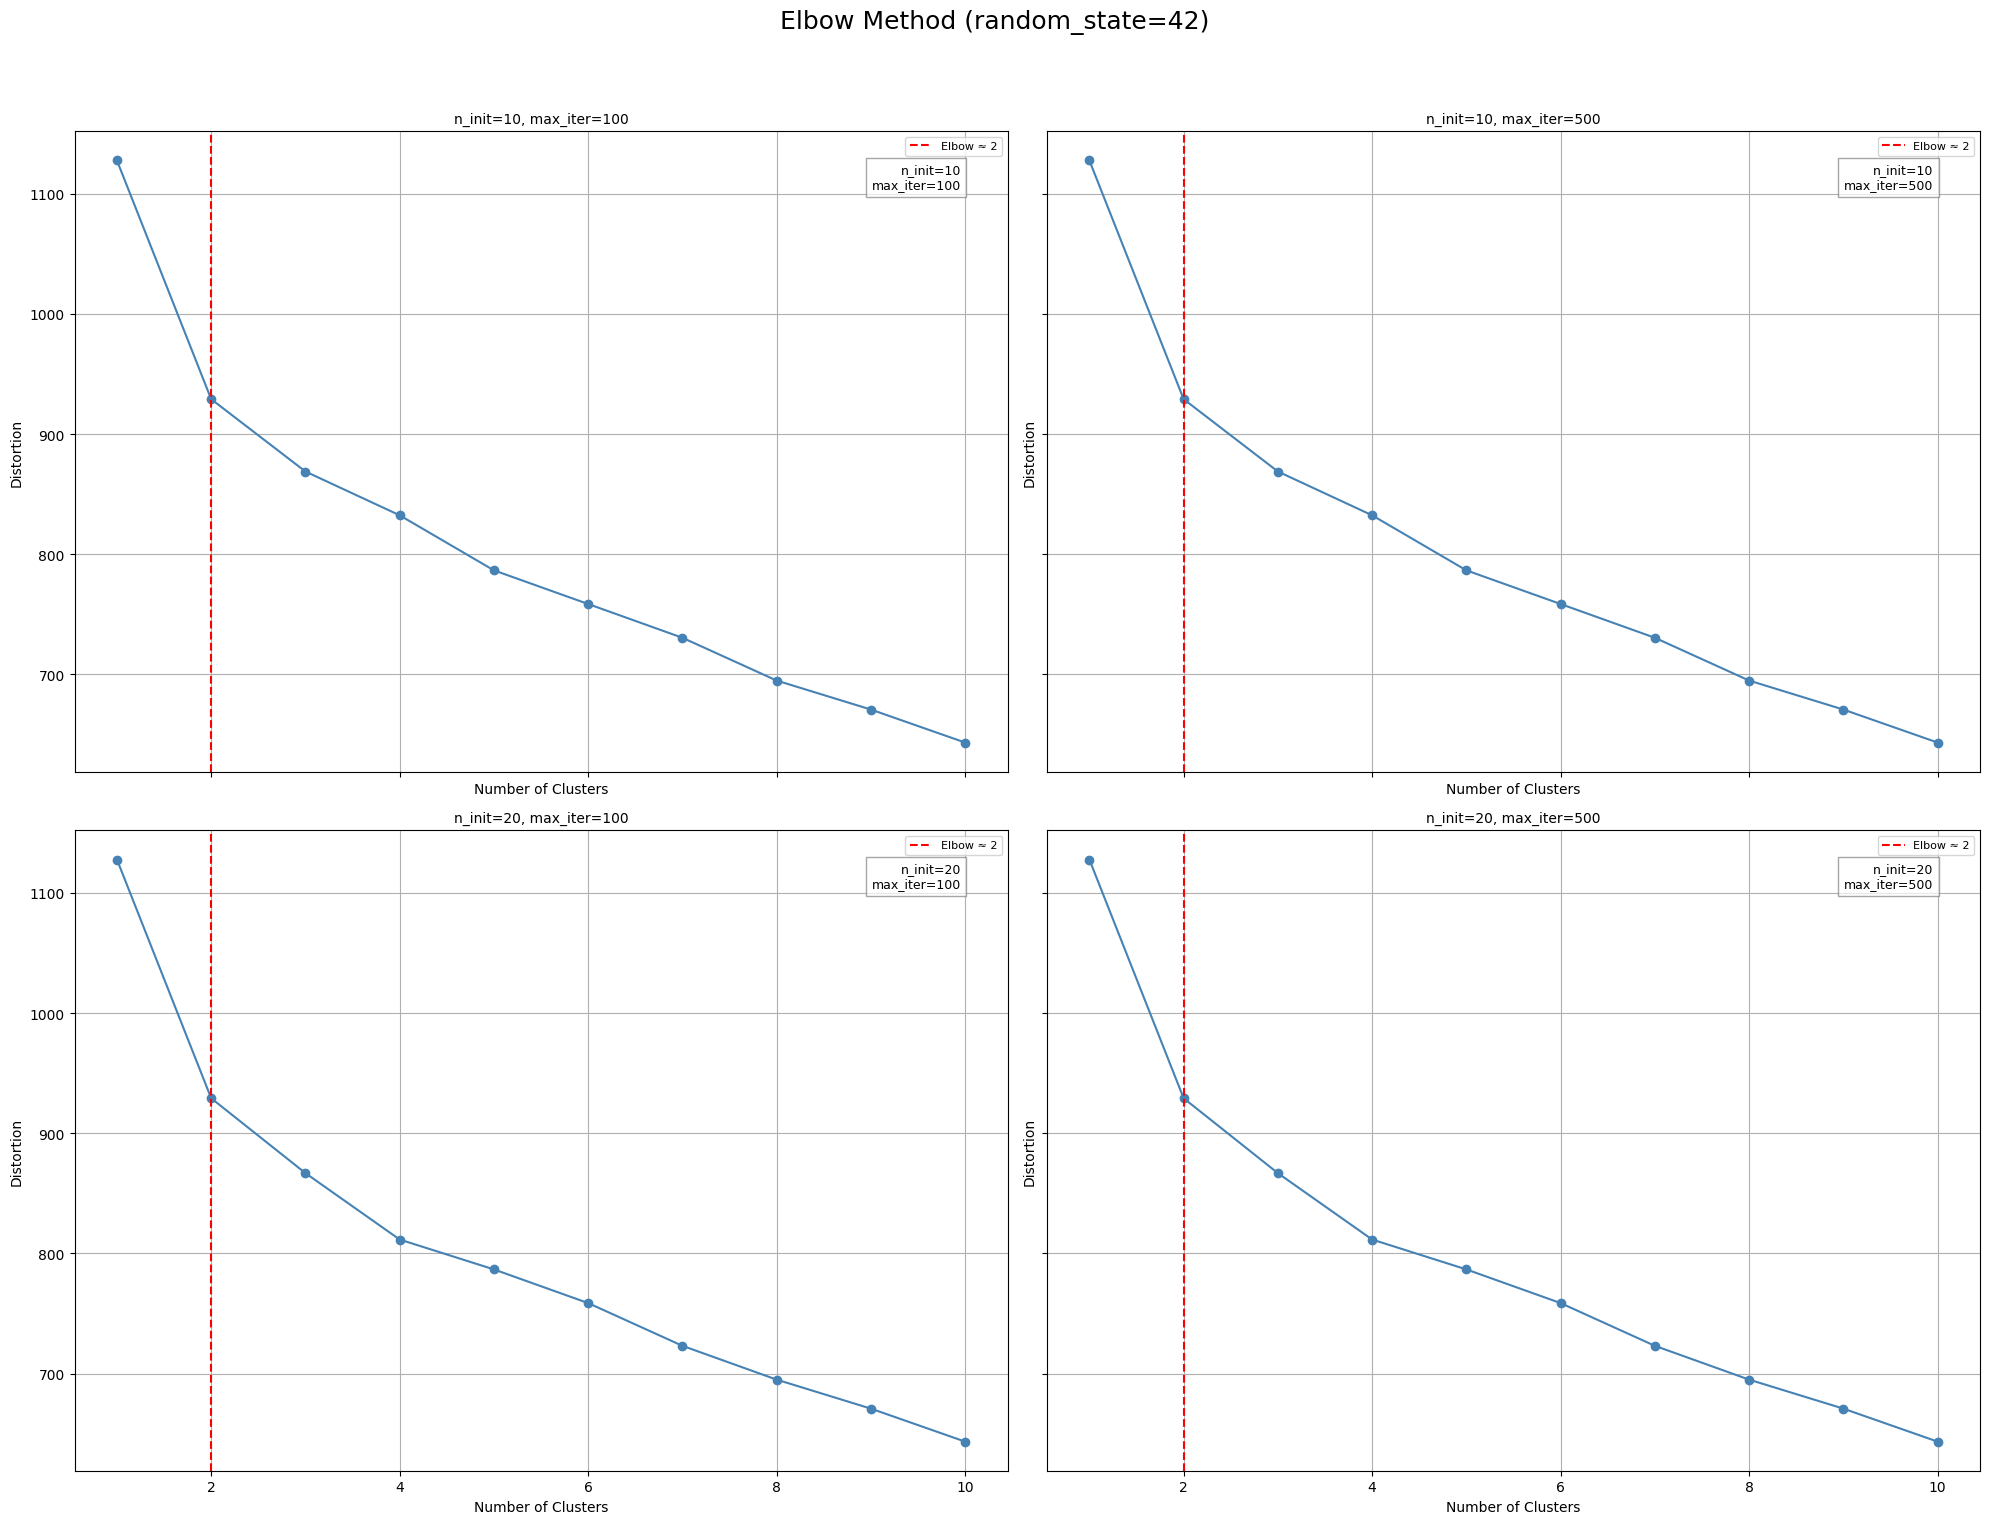


Total execution time: 7.19 seconds


In [15]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(cluster_input)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")